# 01 · EDA de población y variable objetivo

**Objetivo:** entender qué préstamos hay, en qué estado están y qué tan maduros son, para tomar la **decisión 001** (población y definición de "malo").

Fuente: Lending Club, préstamos aprobados 2007–2018 (Kaggle `wordsforthewise/lending-club`, CC0). Corte de los datos: pagos hasta **marzo 2019**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.3f}".format)

# Paleta categórica (orden fijo) y tinta de texto
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

cols = ["loan_status", "term", "issue_d", "loan_amnt", "grade",
        "mort_acc", "bc_util", "mths_since_last_delinq", "dti", "annual_inc"]
df = pd.read_parquet("../data/interim/accepted.parquet", columns=cols)
df["term"] = df["term"].str.strip()
df["anio"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year
df.shape

(2260668, 11)

## 1. ¿Qué estados existen?

In [2]:
estados = df["loan_status"].value_counts().to_frame("prestamos")
estados["%"] = estados["prestamos"] / len(df) * 100
estados

,prestamos,%
loan_status,,
Fully Paid,1076751,47.630
Current,878317,38.852
Charged Off,268559,11.880
Late (31-120 days),21467,0.950
In Grace Period,8436,0.373
Late (16-30 days),4349,0.192
Does not meet the credit policy. Status:Fully Paid,1988,0.088
Does not meet the credit policy. Status:Charged Off,761,0.034
Default,40,0.002


In [3]:
GRUPO = {
    "Fully Paid": "Pagado", "Charged Off": "Castigado", "Default": "Castigado",
    "Current": "Vigente", "In Grace Period": "Mora temprana",
    "Late (16-30 days)": "Mora temprana", "Late (31-120 days)": "Mora 31-120",
}
fuera_politica = df["loan_status"].str.startswith("Does not meet")
df = df[~fuera_politica].copy()
df["grupo"] = df["loan_status"].map(GRUPO)
print(f"Excluidos 'Does not meet the credit policy': {fuera_politica.sum():,}")
df["grupo"].value_counts(normalize=True).mul(100).round(1)

Excluidos 'Does not meet the credit policy': 2,749


grupo
Pagado          47.700
Vigente         38.900
Castigado       11.900
Mora 31-120      1.000
Mora temprana    0.600
Name: proportion, dtype: float64

## 2. Madurez: ¿qué tan "terminados" están los préstamos por año de originación?

Un préstamo a 36 meses originado en dic-2015 vence en dic-2018. Si un año todavía tiene muchos **vigentes**, su tasa de mora observada **no es la definitiva**.

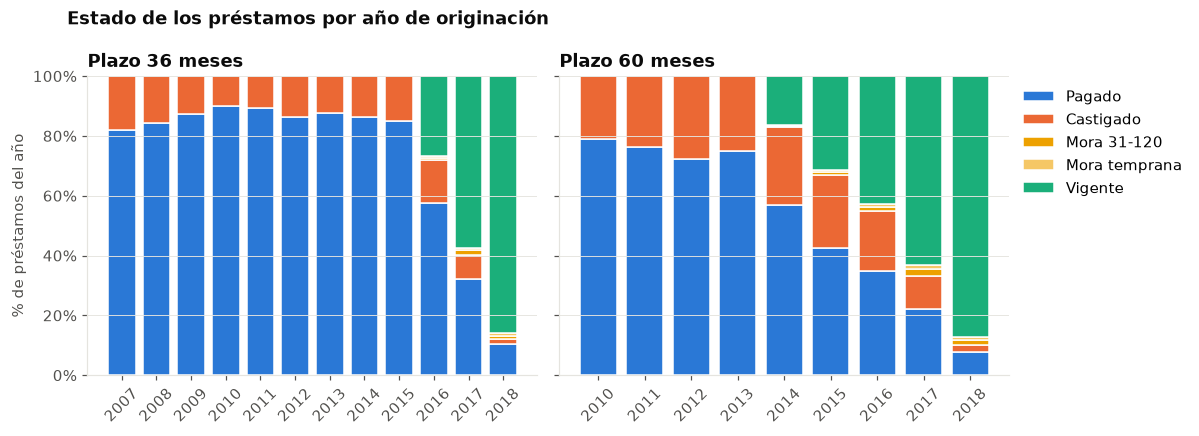

In [4]:
orden = ["Pagado", "Castigado", "Mora 31-120", "Mora temprana", "Vigente"]
comp = pd.crosstab([df["term"], df["anio"]], df["grupo"], normalize="index")[
    [g for g in orden if g in df["grupo"].unique()]]

colores = {"Pagado": AZUL, "Castigado": NARANJA, "Vigente": AQUA,
           "Mora 31-120": AMARILLO, "Mora temprana": "#f5c766"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, plazo in zip(ejes, ["36 months", "60 months"]):
    sub = comp.loc[plazo]
    base = 0
    for g in sub.columns:
        ax.bar(sub.index, sub[g], bottom=base, color=colores[g], label=g,
               edgecolor="white", linewidth=1)
        base = base + sub[g]
    ax.set_title(f"Plazo {plazo.replace('months', 'meses')}")
    ax.set_xticks(sub.index)
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="x", visible=False)
ejes[0].set_ylabel("% de préstamos del año")
ejes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
fig.suptitle("Estado de los préstamos por año de originación", x=0.06, ha="left",
             fontweight="bold", color=TINTA)
fig.tight_layout()

## 3. Tasa de castigo entre préstamos terminados

Malo = *Charged Off* o *Default*; bueno = *Fully Paid*. Se calcula **solo** sobre los préstamos terminados.

tasa_malo           n_terminados           
term 36 months 60 months    36 months  60 months
anio                                            
2007     0.179       NaN      251.000        NaN
2008     0.158       NaN    1,562.000        NaN
2009     0.126       NaN    4,716.000        NaN
2010     0.099     0.210    8,466.000  3,070.000
2011     0.106     0.236   14,101.000  7,620.000
2012     0.136     0.277   43,470.000  9,897.000
2013     0.123     0.251  100,422.000 34,382.000
2014     0.137     0.311  162,570.000 60,533.000
2015     0.149     0.364  283,026.000 92,520.000
2016     0.198     0.364  232,361.000 60,744.000
2017     0.200     0.330  128,551.000 40,770.000
2018     0.132     0.226   41,272.000 15,046.000

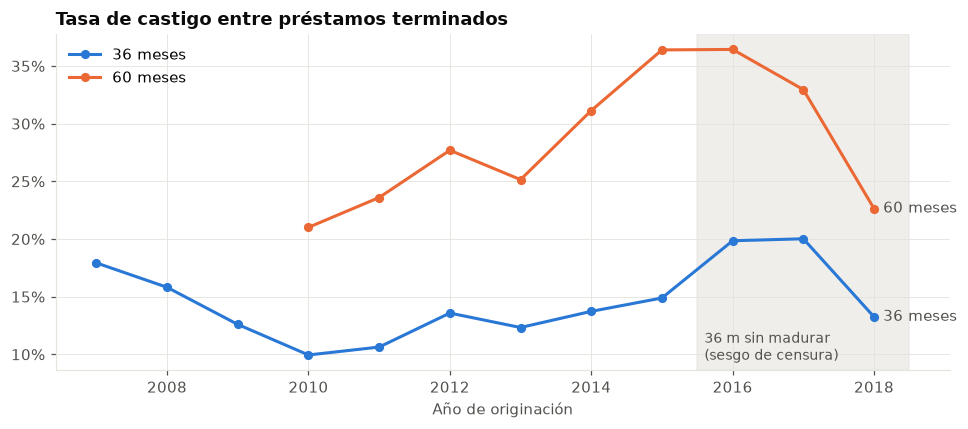

In [5]:
fin = df[df["grupo"].isin(["Pagado", "Castigado"])]
tasa = (fin.assign(malo=fin["grupo"].eq("Castigado"))
          .groupby(["anio", "term"])["malo"].mean().unstack())
n_fin = fin.groupby(["anio", "term"]).size().unstack()

fig, ax = plt.subplots(figsize=(9, 4))
for plazo, color in [("36 months", AZUL), ("60 months", NARANJA)]:
    s = tasa[plazo].dropna()
    ax.plot(s.index, s.values, color=color, linewidth=2, marker="o", markersize=5,
            label=plazo.replace("months", "meses"))
    ax.annotate(plazo.replace("months", "meses"), (s.index[-1], s.values[-1]),
                xytext=(6, 0), textcoords="offset points", color=TINTA_2, va="center")
# Zona donde los préstamos a 36 meses aún no han madurado
ax.axvspan(2015.5, 2018.5, color=GRILLA, alpha=0.6, zorder=0)
ax.text(2015.6, ax.get_ylim()[0] + 0.005, "36 m sin madurar\n(sesgo de censura)",
        color=TINTA_2, fontsize=9, va="bottom")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Tasa de castigo entre préstamos terminados")
ax.set_xlabel("Año de originación")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()

pd.concat({"tasa_malo": tasa, "n_terminados": n_fin}, axis=1)

## 4. ¿Cuánto pesa la mora 31–120 días?

Esto importa para la **opción B** (contarla como malo).

In [6]:
mora = df.groupby("anio")["grupo"].apply(lambda g: g.eq("Mora 31-120").sum())
mora.to_frame("prestamos_mora_31_120").T

anio,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
prestamos_mora_31_120,0,0,0,0,0,0,3,334,1359,4546,8004,7221


## 5. Disponibilidad de variables por año (% de nulos)

In [7]:
(df.groupby("anio")[["mort_acc", "bc_util", "mths_since_last_delinq", "dti", "annual_inc"]]
   .apply(lambda x: x.isna().mean()).mul(100).round(1))

,mort_acc,bc_util,mths_since_last_delinq,dti,annual_inc
anio,,,,,
2007,100.000,100.000,2.400,0.000,0.000
2008,100.000,100.000,41.900,0.000,0.000
2009,100.000,100.000,67.200,0.000,0.000
2010,100.000,100.000,65.100,0.000,0.000
2011,100.000,100.000,66.200,0.000,0.000
2012,14.000,15.100,58.800,0.000,0.000
2013,0.000,0.800,56.500,0.000,0.000
2014,0.000,1.100,49.200,0.000,0.000
2015,0.000,1.000,48.400,0.000,0.000


## 6. Tamaño de las poblaciones candidatas

In [8]:
def resumen(mask, nombre):
    sub = df[mask & df["grupo"].isin(["Pagado", "Castigado"])]
    return {"poblacion": nombre, "prestamos": len(sub),
            "tasa_malo": sub["grupo"].eq("Castigado").mean()}

terminado = df["grupo"].isin(["Pagado", "Castigado"])
pd.DataFrame([
    resumen(terminado, "A · todos los terminados 2007-2018"),
    resumen(df["term"].eq("36 months") & df["anio"].between(2007, 2015), "C · 36 m maduros 2007-2015"),
    resumen(df["term"].eq("36 months") & df["anio"].between(2012, 2015), "C' · 36 m maduros 2012-2015"),
    resumen(df["term"].eq("60 months") & df["anio"].between(2010, 2013), "60 m maduros 2010-2013"),
])

,poblacion,prestamos,tasa_malo
0,A · todos los terminados 2007-2018,1345350,0.200
1,C · 36 m maduros 2007-2015,618584,0.139
2,C' · 36 m maduros 2012-2015,589488,0.140
3,60 m maduros 2010-2013,54969,0.252


## 7. Variables con fuga de información (no se usan como features)

| Variable | Por qué |
|---|---|
| `total_pymnt`, `recoveries`, `out_prncp`, `last_pymnt_d` | Ocurren **después** de la originación |
| `last_fico_range_high` | FICO actualizado durante la vida del préstamo |
| `int_rate`, `grade`, `sub_grade` | Son el **resultado del modelo de riesgo de Lending Club**: usarlos sería copiar su score (decisión pendiente: ¿benchmark?) |
| `hardship_flag`, `debt_settlement_flag` | Se marcan cuando el cliente ya tiene problemas |

---
## ✍️ Conclusiones de Neider

_(Escribe aquí, en tus palabras, qué viste y qué decides. Esto alimenta `docs/decisiones.md`.)_

1.
2.
3. 